In [1]:
from typing import Any, Tuple, NamedTuple, Callable
import time
import jax
from jax import Array
import jax.random as jr
import jax.numpy as jnp
from jax import value_and_grad, jit
from optax import adam, apply_updates
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from diffilqrax.utils import keygen
from diffilqrax.ilqr import ilqr_solver
from diffilqrax.diff_ilqr import dilqr
from diffilqrax.typs import (
    iLQRParams,
    System,
    ModelDims,
)

jax.config.update('jax_enable_x64', True)

In [32]:
class RNNParams(NamedTuple):
    """Parameters for the RNN."""
    Wh: jnp.ndarray
    Wu: jnp.ndarray
    Wo: jnp.ndarray
    bh: jnp.ndarray
    bo: jnp.ndarray
    tau: float
    

# Task parameters
rnn_dim = 4
input_dim = 2
output_dim = 2
dt = 0.05
horizon = 100
control_dim = 2

dims = ModelDims(n=rnn_dim, m=control_dim, horizon=horizon, dt=dt)

In [33]:
def create_rnn_params(key: jnp.ndarray, scale: float = 0.5) -> RNNParams:
    keys = jr.split(key, 6)
    
    Wh = scale * jr.normal(keys[0], (rnn_dim, rnn_dim))

    Wh = Wh.at[0, 0].set(1.2) 
    Wh = Wh.at[1, 1].set(1.2) 
    Wh = Wh.at[0, 1].set(-0.8)
    Wh = Wh.at[1, 0].set(-0.8)
    
    Wu = scale * jr.normal(keys[1], (rnn_dim, input_dim))

    Wu = Wu.at[0, 0].set(2.0) 
    Wu = Wu.at[1, 0].set(-2.0)
    
    Wo = scale * jr.normal(keys[2], (output_dim, rnn_dim))

    Wo = Wo.at[0, 0].set(1.0) 
    Wo = Wo.at[0, 1].set(-1.0)
    Wo = Wo.at[1, :].set(0.5) 
    
    bh = 0.1 * jr.normal(keys[3], (rnn_dim,))
    bo = 0.1 * jr.normal(keys[4], (output_dim,))
    
    tau = 1.0 
    
    return RNNParams(Wh, Wu, Wo, bh, bo, tau)

In [ ]:
"""
Input-driven switch flip state RNN task using iLQR.
The RNN must learn to flip between discrete internal states based on input commands.
"""

import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple, Any, NamedTuple
import time
from functools import partial

from diffilqrax.typs import ModelDims, System, iLQRParams
from diffilqrax.ilqr import ilqr_solver

# Enable double precision for better numerical stability
jax.config.update("jax_enable_x64", True)

# Define RNN parameters
class RNNParams(NamedTuple):
    """RNN parameters for the switch flip task"""
    Wh: jnp.ndarray    # Hidden-to-hidden weight matrix
    Wu: jnp.ndarray    # Input-to-hidden weight matrix  
    Wo: jnp.ndarray    # Hidden-to-output weight matrix
    bh: jnp.ndarray    # Hidden bias
    bo: jnp.ndarray    # Output bias
    tau: float         # Time constant

# Task parameters
rnn_dim = 4           # Hidden state dimension
input_dim = 2         # Input dimension: [switch_command, external_input]
output_dim = 2        # Output dimension: [state_indicator, processed_signal]
dt = 0.05              # Time step
horizon = 200         # Time horizon
control_dim = 2       # Control input dimension (same as input_dim)

# Define system dimensions
dims = ModelDims(n=rnn_dim, m=control_dim, horizon=horizon, dt=dt)

def create_rnn_params(key: jnp.ndarray, scale: float = 0.5) -> RNNParams:
    """
    Create RNN parameters with proper initialization for switch flip dynamics.
    
    Parameters
    ----------
    key : jnp.ndarray
        Random key for initialization
    scale : float
        Scaling factor for weight initialization
        
    Returns
    -------
    RNNParams
        Initialized RNN parameters
    """
    keys = jr.split(key, 6)
    
    # Initialize weights with structured patterns for bistable dynamics
    Wh = scale * jr.normal(keys[0], (rnn_dim, rnn_dim))
    # Add structure for bistable attractor dynamics
    Wh = Wh.at[0, 0].set(1.2)  # Self-reinforcing for state 1
    Wh = Wh.at[1, 1].set(1.2)  # Self-reinforcing for state 2
    Wh = Wh.at[0, 1].set(-0.8) # Mutual inhibition
    Wh = Wh.at[1, 0].set(-0.8) # Mutual inhibition
    
    Wu = scale * jr.normal(keys[1], (rnn_dim, input_dim))
    # Strong input connections for switching
    Wu = Wu.at[0, 0].set(2.0)  # Switch command affects first unit
    Wu = Wu.at[1, 0].set(-2.0) # Switch command affects second unit oppositely
    
    Wo = scale * jr.normal(keys[2], (output_dim, rnn_dim))
    # Output connections to read out state
    Wo = Wo.at[0, 0].set(1.0)  # First output reads first state
    Wo = Wo.at[0, 1].set(-1.0) # With inhibition from second state
    Wo = Wo.at[1, :].set(0.5)  # Second output is weighted sum
    
    bh = 0.1 * jr.normal(keys[3], (rnn_dim,))
    bo = 0.1 * jr.normal(keys[4], (output_dim,))
    
    tau = .5  # Time constant
    
    return RNNParams(Wh, Wu, Wo, bh, bo, tau)

def rnn_dynamics(t: int, h: jnp.ndarray, u: jnp.ndarray, params: RNNParams) -> jnp.ndarray:
    """
    RNN dynamics with switch flip behavior.
    
    The RNN evolves according to:
    τ dh/dt = -h + tanh(Wh @ h + Wu @ u + bh)
    
    Parameters
    ----------
    t : int
        Time step
    h : jnp.ndarray
        Hidden state [rnn_dim]
    u : jnp.ndarray
        Control input [switch_command, external_input]
    params : RNNParams
        RNN parameters
        
    Returns
    -------
    jnp.ndarray
        Next hidden state
    """
    # Continuous RNN dynamics
    h_dot = (-h + jnp.tanh(params.Wh @ h + params.Wu @ u + params.bh)) / params.tau
    
    # Discretize using Euler integration
    h_next = h + h_dot * dt
    
    return h_next

def rnn_output(h: jnp.ndarray, params: RNNParams) -> jnp.ndarray:
    """
    Compute RNN output from hidden state.
    
    Parameters
    ----------
    h : jnp.ndarray
        Hidden state
    params : RNNParams
        RNN parameters
        
    Returns
    -------
    jnp.ndarray
        Output [state_indicator, processed_signal]
    """
    return jnp.tanh(params.Wo @ h + params.bo)

def generate_switch_sequence(key: jnp.ndarray, horizon: int) -> Tuple[jnp.ndarray, jnp.ndarray]:
    """
    Generate target switch sequence and external input signal.
    
    Parameters
    ----------
    key : jnp.ndarray
        Random key
    horizon : int
        Time horizon
        
    Returns
    -------
    Tuple[jnp.ndarray, jnp.ndarray]
        Target switch states and external input signal
    """
    keys = jr.split(key, 3)
    
    # Generate switch times (when to flip state)
    switch_probability = 0.05  # 5% chance per timestep
    switch_events = jr.bernoulli(keys[0], switch_probability, (horizon,))
    
    # Generate target switch states (cumulative switches mod 2)
    target_states = jnp.cumsum(switch_events) % 2
    # Convert to [-1, 1] range
    target_states = (2 * target_states - 1)*1.0
    
    # Generate external input signal (sinusoidal with noise)
    t_vals = jnp.arange(horizon) * dt
    external_signal = (jnp.sin(0.5 * t_vals) + 
                      0.3 * jnp.sin(2.0 * t_vals) + 
                      0.1 * jr.normal(keys[1], (horizon,)))
    
    # Generate switch commands (1 when switch occurs, 0 otherwise)
    switch_commands = switch_events.astype(jnp.float32)
    
    return target_states, external_signal, switch_commands

def switch_flip_cost(t: int, h: jnp.ndarray, u: jnp.ndarray, params: Any) -> jnp.ndarray:
    """
    Cost function for the switch flip task.
    
    The RNN should:
    1. Flip between two stable states when commanded
    2. Process external input signal based on current state
    3. Maintain states with minimal control effort
    
    Parameters
    ----------
    t : int
        Time step
    h : jnp.ndarray
        Hidden state
    u : jnp.ndarray
        Control input
    params : Any
        Task parameters containing RNN params and targets
        
    Returns
    -------
    jnp.ndarray
        Scalar cost
    """
    rnn_params, target_states, external_signal, switch_commands = params
    
    # Compute RNN output
    output = rnn_output(h, rnn_params)
    state_indicator = output[0]
    processed_signal = output[1]
    
    # Target state tracking cost
    target_state = target_states[t]
    state_tracking_cost = 10.0 * (state_indicator - target_state)**2
    
    # Signal processing cost (when in state +1, amplify signal; when in state -1, attenuate)
    expected_processing = jnp.where(
        target_state > 0,
        external_signal[t],           # Amplify when in state +1
        0.1 * external_signal[t]      # Attenuate when in state -1
    )
    signal_processing_cost = 5.0 * (processed_signal - expected_processing)**2
    
    # State stability cost (encourage bistable dynamics)
    stability_cost = 2.0 * jnp.sum(jnp.maximum(0, 1.0 - jnp.abs(h[:2]))**2)
    
    # Control effort cost
    control_cost = 0.1 * jnp.sum(u**2)
    
    # Switch command utilization (encourage using switch commands effectively)
    switch_command = u[0]
    command_cost = 1.0 * (switch_command - switch_commands[t])**2
    
    return (state_tracking_cost + 
            signal_processing_cost + 
            stability_cost + 
            control_cost + 
            command_cost)

def switch_flip_costf(h: jnp.ndarray, params: Any) -> jnp.ndarray:
    """
    Terminal cost function for the switch flip task.
    
    Parameters
    ----------
    h : jnp.ndarray
        Final hidden state
    params : Any
        Task parameters
        
    Returns
    -------
    jnp.ndarray
        Scalar terminal cost
    """
    rnn_params, target_states, external_signal, switch_commands = params
    
    # Compute final output
    output = rnn_output(h, rnn_params)
    state_indicator = output[0]
    
    # Final state tracking cost
    target_final_state = target_states[-1]
    final_state_cost = 20.0 * (state_indicator - target_final_state)**2
    
    # Final state stability cost
    final_stability_cost = 5.0 * jnp.sum(jnp.maximum(0, 1.0 - jnp.abs(h[:2]))**2)
    
    return final_state_cost + final_stability_cost

def simulate_rnn_task(rnn_params: RNNParams, 
                     target_states: jnp.ndarray,
                     external_signal: jnp.ndarray,
                     switch_commands: jnp.ndarray,
                     Us: jnp.ndarray,
                     h0: jnp.ndarray) -> Tuple[jnp.ndarray, jnp.ndarray]:
    """
    Simulate the RNN switch flip task.
    
    Parameters
    ----------
    rnn_params : RNNParams
        RNN parameters
    target_states : jnp.ndarray
        Target switch states
    external_signal : jnp.ndarray
        External input signal
    switch_commands : jnp.ndarray
        Switch command sequence
    Us : jnp.ndarray
        Control inputs
    h0 : jnp.ndarray
        Initial hidden state
        
    Returns
    -------
    Tuple[jnp.ndarray, jnp.ndarray]
        Hidden state trajectory and output trajectory
    """
    def step_fn(h, inputs):
        t, u = inputs
        h_next = rnn_dynamics(t, h, u, rnn_params)
        output = rnn_output(h_next, rnn_params)
        return h_next, (h_next, output)
    
    t_vals = jnp.arange(horizon)
    _, (h_traj, output_traj) = jax.lax.scan(step_fn, h0, (t_vals, Us))
    
    # Add initial state to trajectory
    h_traj = jnp.vstack([h0[None], h_traj])
    
    return h_traj, output_traj

def run_switch_flip_experiment(seed: int = 42):
    """
    Run the complete switch flip RNN experiment with iLQR.
    
    Parameters
    ----------
    seed : int
        Random seed for reproducibility
        
    Returns
    -------
    Tuple
        Results including trajectories and costs
    """
    key = jr.PRNGKey(seed)
    keys = jr.split(key, 4)
    
    print("Initializing switch flip RNN task...")
    
    # Create RNN parameters
    rnn_params = create_rnn_params(keys[0])
    
    # Generate task sequence
    target_states, external_signal, switch_commands = generate_switch_sequence(keys[1], horizon)
    
    # Initial hidden state (start in neutral state)
    h0 = 0.1 * jr.normal(keys[2], (rnn_dim,))
    
    # Package parameters for cost function
    task_params = (rnn_params, target_states, external_signal, switch_commands)
    
    # Create system model
    def dynamics_wrapper(t, h, u, params):
        return rnn_dynamics(t, h, u, params[0])
    
    def cost_wrapper(t, h, u, params):
        return switch_flip_cost(t, h, u, params)
    
    def costf_wrapper(h, params):
        return switch_flip_costf(h, params)
    
    model = System(cost_wrapper, costf_wrapper, dynamics_wrapper, dims)
    
    
    # Set up iLQR parameters
    ilqr_params = iLQRParams(x0=h0, theta=task_params)
    
    # Initialize control sequence
    Us_init = 0.1 * jr.normal(keys[3], (horizon, control_dim))
    
    # Run iLQR solver
    print("Running iLQR solver for switch flip task...")
    start_time = time.time()
    
    # Line search parameters
    ls_kwargs = {
        "beta": 0.8,
        "max_iter_linesearch": 28,
        "tol": 0.05,
        "alpha_min": 1e-5,
    }
    
    # Run solver
    ((Hs_star, Us_star, Lambdas_star), total_cost, costs) = ilqr_solver(
        model, ilqr_params, Us_init,
        max_iter=200,
        convergence_thresh=1e-6,
        use_linesearch=True,
        verbose=True,
        **ls_kwargs
    )
    
    end_time = time.time()
    print(f"Optimization completed in {end_time - start_time:.2f} seconds")
    print(f"Final cost: {total_cost:.4f}")
    print(f"Iterations: {len(costs) - 1}")
    
    # Simulate optimized trajectory
    h_traj, output_traj = simulate_rnn_task(
        rnn_params, target_states, external_signal, switch_commands, Us_star, h0
    )
    
    return {
        'rnn_params': rnn_params,
        'target_states': target_states,
        'external_signal': external_signal,
        'switch_commands': switch_commands,
        'h_trajectory': h_traj,
        'output_trajectory': output_traj,
        'control_inputs': Us_star,
        'costs': costs,
        'total_cost': total_cost
    }

def plot_switch_flip_results(results):
    """
    Plot the results of the switch flip RNN experiment.
    
    Parameters
    ----------
    results : dict
        Results from run_switch_flip_experiment
    """
    # Extract results
    target_states = results['target_states']
    external_signal = results['external_signal']
    switch_commands = results['switch_commands']
    h_traj = np.array(results['h_trajectory'])
    output_traj = np.array(results['output_trajectory'])
    Us_star = np.array(results['control_inputs'])
    costs = results['costs']
    
    # Create time vector
    t_vals = np.arange(horizon) * dt
    t_vals_h = np.arange(horizon + 1) * dt
    
    # Set up the figure
    fig = plt.figure(figsize=(16, 12))
    
    # Plot 1: Hidden state dynamics
    ax1 = fig.add_subplot(321)
    ax1.set_title('RNN Hidden State Dynamics')
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Hidden State')
    
    for i in range(min(4, rnn_dim)):
        ax1.plot(t_vals_h, h_traj[:, i], label=f'h_{i+1}')
    
    ax1.grid(True)
    ax1.legend()
    
    # Plot 2: State tracking performance
    ax2 = fig.add_subplot(322)
    ax2.set_title('State Tracking Performance')
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('State Value')
    
    ax2.plot(t_vals, target_states, 'k--', linewidth=2, label='Target State')
    ax2.plot(t_vals, output_traj[:, 0], 'r-', linewidth=2, label='RNN State Output')
    
    # Mark switch events
    switch_times = t_vals[switch_commands > 0.5]
    for st in switch_times:
        ax2.axvline(st, color='blue', alpha=0.3, linestyle=':', label='Switch Command' if st == switch_times[0] else "")
    
    ax2.set_ylim([-1.5, 1.5])
    ax2.grid(True)
    ax2.legend()
    
    # Plot 3: Signal processing
    ax3 = fig.add_subplot(323)
    ax3.set_title('Signal Processing Performance')
    ax3.set_xlabel('Time (s)')
    ax3.set_ylabel('Signal Value')
    
    ax3.plot(t_vals, external_signal, 'g-', alpha=0.7, label='External Signal')
    ax3.plot(t_vals, output_traj[:, 1], 'purple', linewidth=2, label='Processed Signal')
    
    # Show expected processing based on state
    expected_processing = np.where(
        target_states > 0,
        external_signal,
        0.1 * external_signal
    )
    ax3.plot(t_vals, expected_processing, 'orange', linestyle='--', label='Expected Processing')
    
    ax3.grid(True)
    ax3.legend()
    
    # Plot 4: Control inputs
    ax4 = fig.add_subplot(324)
    ax4.set_title('Control Inputs')
    ax4.set_xlabel('Time (s)')
    ax4.set_ylabel('Control Value')
    
    ax4.plot(t_vals, Us_star[:, 0], 'b-', label='Switch Command Control')
    ax4.plot(t_vals, Us_star[:, 1], 'cyan', label='External Input Control')
    ax4.plot(t_vals, switch_commands, 'k:', alpha=0.5, label='Target Switch Commands')
    
    ax4.grid(True)
    ax4.legend()
    
    # Plot 5: Cost convergence
    ax5 = fig.add_subplot(325)
    ax5.set_title('iLQR Cost Convergence')
    ax5.set_xlabel('Iteration')
    ax5.set_ylabel('Cost (log scale)')
    ax5.semilogy(costs, 'b-o')
    ax5.grid(True)
    
    # Plot 6: Phase portrait of first two hidden units
    ax6 = fig.add_subplot(326)
    ax6.set_title('Phase Portrait (h1 vs h2)')
    ax6.set_xlabel('Hidden Unit 1')
    ax6.set_ylabel('Hidden Unit 2')
    
    # Color trajectory by target state
    scatter = ax6.scatter(h_traj[:-1, 0], h_traj[:-1, 1], 
                         c=target_states, cmap='RdBu', s=20, alpha=0.7)
    plt.colorbar(scatter, ax=ax6, label='Target State')
    
    # Mark start and end points
    ax6.plot(h_traj[0, 0], h_traj[0, 1], 'go', markersize=8, label='Start')
    ax6.plot(h_traj[-1, 0], h_traj[-1, 1], 'rs', markersize=8, label='End')
    
    ax6.grid(True)
    ax6.legend()
    
    plt.tight_layout()
    
    # Performance metrics
    state_error = np.mean((output_traj[:, 0] - target_states)**2)
    switch_accuracy = np.mean(np.abs(Us_star[:, 0] - switch_commands) < 0.3)
    
    print(f"\nPerformance Metrics:")
    print(f"State tracking MSE: {state_error:.4f}")
    print(f"Switch command accuracy: {switch_accuracy:.2%}")
    print(f"Final cost: {results['total_cost']:.4f}")

def analyze_switch_dynamics(results):
    """
    Analyze the switch dynamics and bistability of the learned RNN.
    
    Parameters
    ----------
    results : dict
        Results from run_switch_flip_experiment
    """
    rnn_params = results['rnn_params']
    h_traj = results['h_trajectory']
    
    print("\nAnalyzing RNN switch dynamics...")
    
    # Find attractors by examining fixed points
    def rnn_field(h):
        """RNN vector field with zero input"""
        return (-h + jnp.tanh(rnn_params.Wh @ h + rnn_params.bh)) / rnn_params.tau
    
    # Analyze eigenvalues of Jacobian at different points
    jac_fn = jax.jacfwd(rnn_field)
    
    # Sample points along trajectory
    sample_points = h_traj[::10]  # Sample every 10 time steps
    
    print("Eigenvalue analysis at sample points:")
    for i, h in enumerate(sample_points[:5]):  # Analyze first 5 sample points
        jac = jac_fn(h)
        eigenvals = jnp.linalg.eigvals(jac)
        max_real = jnp.max(jnp.real(eigenvals))
        print(f"Point {i}: Max real eigenvalue = {max_real:.3f}")
    
    # Compute state persistence (how long states are maintained)
    output_states = results['output_trajectory'][:, 0]
    state_changes = jnp.abs(jnp.diff(output_states)) > 0.5
    switch_times = jnp.where(state_changes)[0]
    
    if len(switch_times) > 1:
        persistence_times = jnp.diff(switch_times) * dt
        mean_persistence = jnp.mean(persistence_times)
        print(f"Mean state persistence time: {mean_persistence:.2f} seconds")
    
    print("Switch dynamics analysis complete.")

def main():
    """Main function to run the switch flip RNN experiment."""
    print("Input-Driven Switch Flip RNN Task with iLQR")
    print("=" * 50)
    print(f"RNN dimension: {rnn_dim}")
    print(f"Time horizon: {horizon} steps ({horizon * dt:.1f} seconds)")
    print(f"Control dimension: {control_dim}")
    
    # Run experiment
    results = run_switch_flip_experiment(seed=42)
    
    # Plot results
    print("\nPlotting results...")
    plot_switch_flip_results(results)
    
    # Analyze dynamics
    analyze_switch_dynamics(results)
    
    print(f"\nExperiment completed successfully!")
    print("Results saved to 'rnn_switch_flip_results.png'")


Input-Driven Switch Flip RNN Task with iLQR
RNN dimension: 4
Time horizon: 200 steps (10.0 seconds)
Control dimension: 2
Initializing switch flip RNN task...
Running iLQR solver for switch flip task...
Converged in 10/200 iterations
old_cost: 3910.0875351369773
Optimization completed in 2.15 seconds
Final cost: 3910.0875
Iterations: 200

Plotting results...

Performance Metrics:
State tracking MSE: 1.7663
Switch command accuracy: 30.00%
Final cost: 3910.0875

Analyzing RNN switch dynamics...
Eigenvalue analysis at sample points:
Point 0: Max real eigenvalue = 1.341
Point 1: Max real eigenvalue = -1.181
Point 2: Max real eigenvalue = -1.648
Point 3: Max real eigenvalue = -1.559
Point 4: Max real eigenvalue = -1.678
Switch dynamics analysis complete.

Experiment completed successfully!
Results saved to 'rnn_switch_flip_results.png'


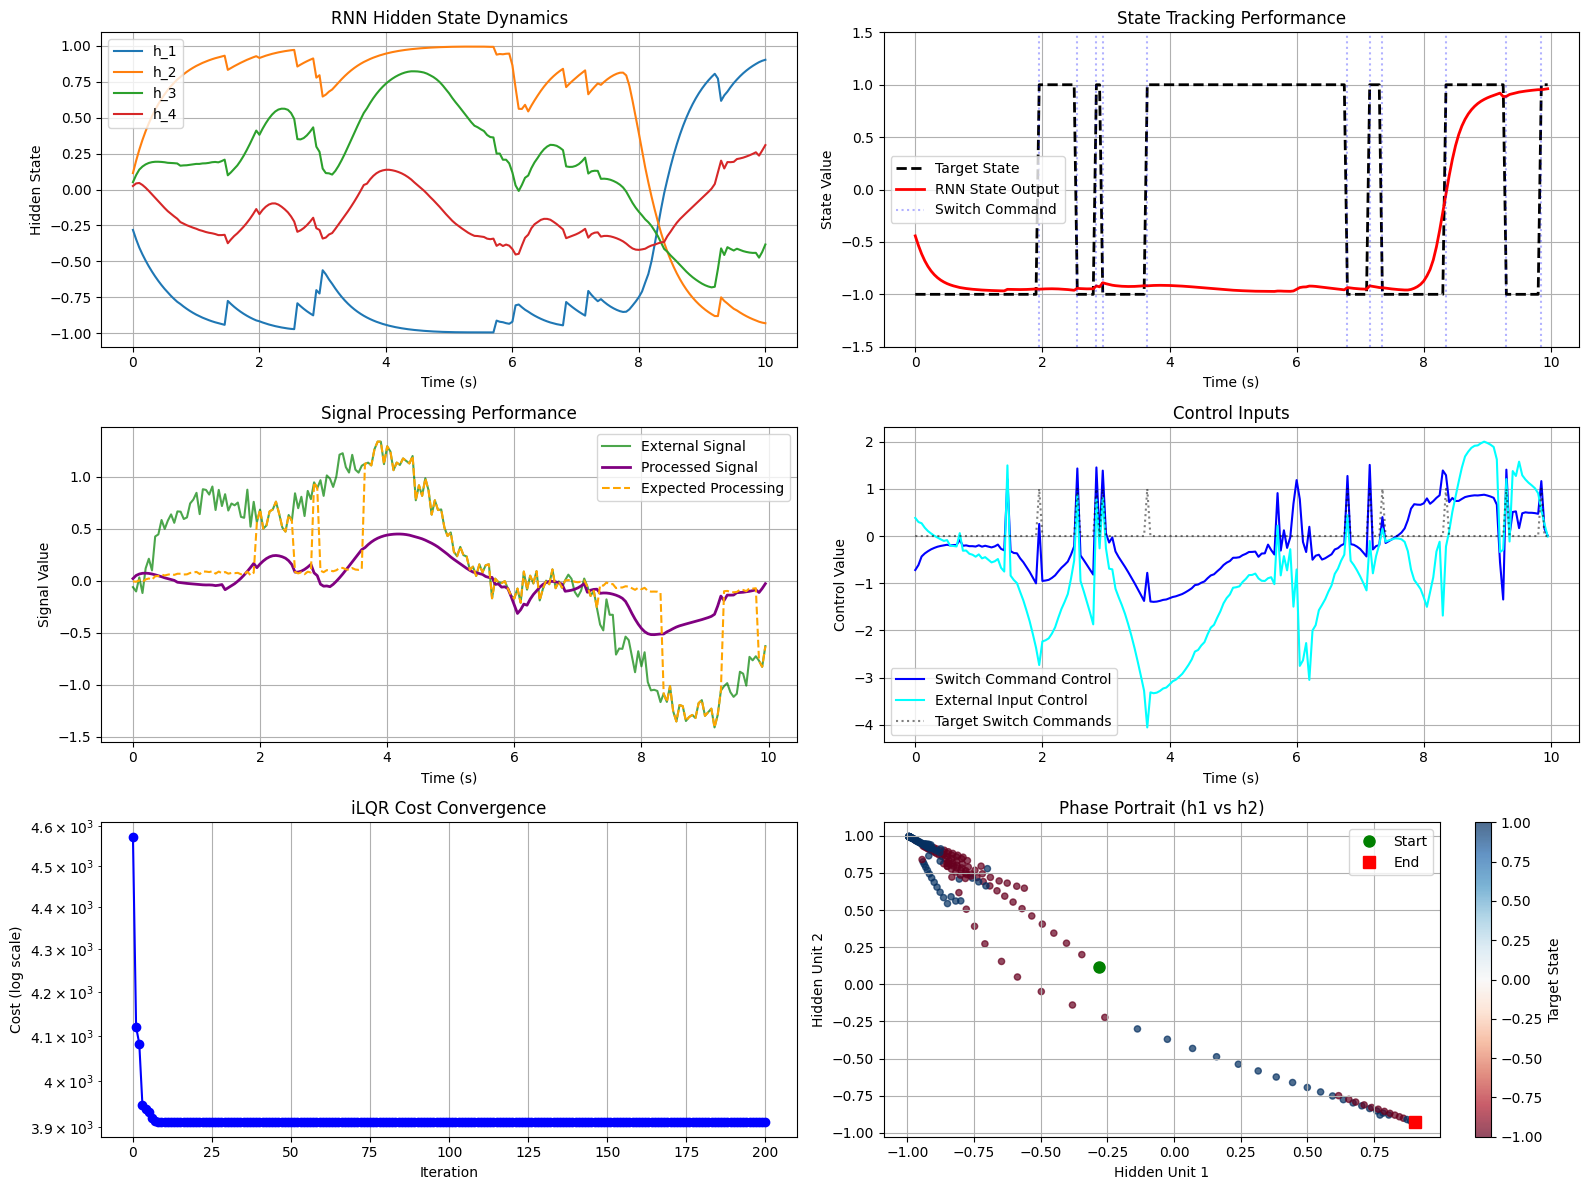

In [77]:
main()


In [78]:
from diffilqrax.ilqr import ilqr_simulate
from diffilqrax.diff_ilqr import dilqr

seed=42
key = jr.PRNGKey(seed)
keys = jr.split(key, 4)

print("Initializing switch flip RNN task...")

# Create RNN parameters
rnn_params = create_rnn_params(keys[0])

# Generate task sequence
target_states, external_signal, switch_commands = generate_switch_sequence(keys[1], horizon)

# Initial hidden state (start in neutral state)
h0 = 0.1 * jr.normal(keys[2], (rnn_dim,))

# Package parameters for cost function
task_params = (rnn_params, target_states, external_signal, switch_commands)

# Create system model
def dynamics_wrapper(t, h, u, params):
    return rnn_dynamics(t, h, u, params[0])

def cost_wrapper(t, h, u, params):
    return switch_flip_cost(t, h, u, params)

def costf_wrapper(h, params):
    return switch_flip_costf(h, params)

model = System(cost_wrapper, costf_wrapper, dynamics_wrapper, dims)

# Set up iLQR parameters
ilqr_params = iLQRParams(x0=h0, theta=task_params)

# Initialize control sequence
Us_init = 0.1 * jr.normal(keys[3], (horizon, control_dim))

# Run iLQR solver
print("Running iLQR solver for switch flip task...")
start_time = time.time()

# Line search parameters
ls_kwargs = {
    "beta": 0.8,
    "max_iter_linesearch": 28,
    "tol": 0.05,
    "alpha_min": 1e-5,
}

# Run solver
opt_traj = dilqr(
    model, ilqr_params, Us_init,
    max_iter=200,
    convergence_thresh=1e-6,
    use_linesearch=True,
    verbose=True,
    **ls_kwargs
)
end_time = time.time()

Initializing switch flip RNN task...
Running iLQR solver for switch flip task...
Converged in 10/200 iterations
old_cost: 3910.0875351369773


In [79]:
opt_state, opt_control = opt_traj[:,:dims.n], opt_traj[:-1,dims.n:]

In [80]:
(opt_x, opt_u), total_cost = ilqr_simulate(model, opt_control, ilqr_params)

In [81]:



print(f"Optimization completed in {end_time - start_time:.2f} seconds")
print(f"Final cost: {total_cost:.4f}")

# Simulate optimized trajectory
h_traj, output_traj = simulate_rnn_task(
    rnn_params, target_states, external_signal, switch_commands, opt_u, h0
)

res = {
    'rnn_params': rnn_params,
    'target_states': target_states,
    'external_signal': external_signal,
    'switch_commands': switch_commands,
    'h_trajectory': h_traj,
    'output_trajectory': output_traj,
    'control_inputs': opt_u,
    'total_cost': total_cost
}

Optimization completed in 2.10 seconds
Final cost: 3910.0875


In [82]:
ilqr_params.theta

(RNNParams(Wh=Array([[ 1.2       , -0.8       ,  0.07960148,  0.54131169],
        [-0.8       ,  1.2       ,  1.21067055,  0.76805037],
        [-0.25079022,  0.00803637, -0.48373969,  0.57111801],
        [ 0.55833155, -0.21395465, -0.37951969, -0.51577927]],      dtype=float64), Wu=Array([[ 2.        ,  0.30416399],
        [-2.        ,  0.25651996],
        [-0.8930423 , -0.15521783],
        [-0.57835167, -0.12820835]], dtype=float64), Wo=Array([[ 1.        , -1.        ,  0.29581182,  0.76831166],
        [ 0.5       ,  0.5       ,  0.5       ,  0.5       ]],      dtype=float64), bh=Array([ 0.08386388,  0.08620528, -0.03949023,  0.05201545], dtype=float64), bo=Array([0.00862587, 0.02169999], dtype=float64), tau=0.5),
 Array([-1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.,
        -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.,
        -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.,
         1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,

In [89]:
from jax import value_and_grad

def ilqr_solver_cost_function(params: iLQRParams, Us_init: jnp.ndarray):
# def ilqr_solver_cost_function(params: iLQRParams):
    tau_star = dilqr(
        model,
        params,
        Us_init,
        max_iter=70,
        convergence_thresh=1e-9,
        alpha_init=1.0,
        use_linesearch=True,
        **ls_kwargs,
    )
    opt_xs = tau_star[:, : dims.n]
    opt_us = tau_star[:, dims.n :]
    return jnp.linalg.norm(opt_xs) ** 2 + jnp.linalg.norm(opt_us) ** 2

value, grad = value_and_grad(ilqr_solver_cost_function,argnums=(0,1))(ilqr_params, Us_init)
# value, grad = value_and_grad(ilqr_solver_cost_function)(ilqr_params)

In [90]:
grad

(iLQRParams(x0=Array([-12.5605286 ,   1.6221597 ,   2.87481453,   0.74460427], dtype=float64), theta=(RNNParams(Wh=Array([[  38.55615805,  -39.8512369 ,  -13.70695715,    6.06889764],
        [  80.88956913,  -90.72999801,  -46.6028289 ,   16.77218384],
        [ 319.5608683 , -342.14050604, -153.9161223 ,   81.29988853],
        [ 126.51499216, -196.9459905 ,  197.95365833,  448.22457372]],      dtype=float64), Wu=Array([[  -36.00885919,  -109.40785571],
        [  -55.21378105,   150.13493928],
        [  299.65862013,  -136.145881  ],
        [ -179.45919043, -5284.49834814]], dtype=float64), Wo=Array([[-1082.25120348,  1046.92095434,  1098.85145513,   550.75190917],
        [ 1275.44175614, -1385.09466115,  -430.3675553 ,   726.06880227]],      dtype=float64), bh=Array([ -26.85350057,  -69.97205025, -251.72076504,  -17.45103513],      dtype=float64), bo=Array([1200.959377 , -997.4497452], dtype=float64), tau=Array(-56.57887819, dtype=float64, weak_type=True)), Array([ 0.00000000e+0

In [65]:

value, grad.shape

(Array(852.23884682, dtype=float64), (200, 2))